# Late Delivery Prediction
Predict at purchase time whether an order will arrive late. Only information available when the order is placed is used.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix
from sklearn.model_selection import KFold

In [2]:
path = "../Data/Processed/"

orders = pd.read_csv(path + "orders_clean.csv", parse_dates=["order_purchase_timestamp", "order_estimated_delivery_date"])
items = pd.read_csv(path + "order_items_clean.csv")
products = pd.read_csv(path + "products_clean.csv")
customers = pd.read_csv(path + "customers_clean.csv", dtype={"customer_zip_code_prefix": str})
sellers = pd.read_csv(path + "sellers_clean.csv", dtype={"seller_zip_code_prefix": str})
geo = pd.read_csv(path + "geolocation_by_zip_clean.csv", dtype={"geolocation_zip_code_prefix": str})

scope = orders[orders["in_analysis_scope"] == True].copy()
print(len(scope), "orders, late rate", round(scope["is_late"].mean() * 100, 2), "%")

96470 orders, late rate 6.77 %


### What do we know about an order when it is placed?

In [3]:
items = items.merge(products[["product_id", "product_category_name_english", "product_weight_g",
                              "product_length_cm", "product_height_cm", "product_width_cm"]], on="product_id", how="left")
items["volume"] = items["product_length_cm"] * items["product_height_cm"] * items["product_width_cm"]

order_items = items.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    price=("price", "sum"),
    freight=("freight_value", "sum"),
    weight=("product_weight_g", "sum"),
    max_volume=("volume", "max"),
    n_sellers=("seller_id", "nunique")).reset_index()

# category and seller of the first item
first_item = items[items["order_item_id"] == 1][["order_id", "product_category_name_english", "seller_id"]]

df = scope[["order_id", "customer_id", "order_purchase_timestamp", "order_estimated_delivery_date", "is_late"]]
df = df.merge(order_items, on="order_id").merge(first_item, on="order_id", how="left")
df["freight_ratio"] = df["freight"] / df["price"]

df = df.merge(customers[["customer_id", "customer_state", "customer_zip_code_prefix"]], on="customer_id", how="left")
df = df.merge(sellers[["seller_id", "seller_state", "seller_zip_code_prefix"]], on="seller_id", how="left")
df["same_state"] = (df["customer_state"] == df["seller_state"]).astype(int)
df.head()

,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,is_late,n_items,price,freight,weight,max_volume,n_sellers,product_category_name_english,seller_id,freight_ratio,customer_state,customer_zip_code_prefix,seller_state,seller_zip_code_prefix,same_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,2017-10-02 10:56:33,2017-10-18,False,1,29.99,8.72,500.0,1976.0,1,housewares,3504c0cb71d7fa48d967e0e4c94d59d9,0.290764,SP,03149,SP,09350,1
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,2018-07-24 20:41:37,2018-08-13,False,1,118.70,22.76,400.0,4693.0,1,perfumery,289cdb325fb7e7f891c38608bf9e0962,0.191744,BA,47813,SP,31570,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,2018-08-08 08:38:49,2018-09-04,False,1,159.90,19.22,420.0,9576.0,1,auto,4869f7a5dfa277a7dca6462dcf3b52b2,0.120200,GO,75265,SP,14840,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,2017-11-18 19:28:06,2017-12-15,False,1,45.00,27.20,450.0,6000.0,1,pet_shop,66922902710d126a0e7d26b0e3805106,0.604444,RN,59296,MG,31842,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,2018-02-13 21:18:39,2018-02-26,False,1,19.90,8.72,250.0,11475.0,1,stationery,2c9e548be18521d1c43cde1c582c6de8,0.438191,SP,09195,SP,08752,1


In [4]:
geo = geo[["geolocation_zip_code_prefix", "geolocation_lat", "geolocation_lng"]]
cust_geo = geo.rename(columns={"geolocation_zip_code_prefix": "customer_zip_code_prefix", "geolocation_lat": "c_lat", "geolocation_lng": "c_lng"})
sell_geo = geo.rename(columns={"geolocation_zip_code_prefix": "seller_zip_code_prefix", "geolocation_lat": "s_lat", "geolocation_lng": "s_lng"})
df = df.merge(cust_geo, on="customer_zip_code_prefix", how="left").merge(sell_geo, on="seller_zip_code_prefix", how="left")

# haversine distance in km
lat1, lng1, lat2, lng2 = [np.radians(df[c]) for c in ["c_lat", "c_lng", "s_lat", "s_lng"]]
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

df["weekday"] = df["order_purchase_timestamp"].dt.dayofweek
df["hour"] = df["order_purchase_timestamp"].dt.hour
df["estimated_days"] = (df["order_estimated_delivery_date"] - df["order_purchase_timestamp"].dt.normalize()).dt.days

print("missing distance:", df["distance_km"].isna().sum())
df[["distance_km", "estimated_days", "freight_ratio", "weight"]].describe().round(1)

missing distance: 479


,distance_km,estimated_days,freight_ratio,weight
count,95991.0,96470.0,96470.0,96470.0
mean,600.4,24.4,0.3,2386.5
std,592.4,8.8,0.3,4769.8
min,0.0,3.0,0.0,0.0
25%,185.0,19.0,0.1,300.0
50%,433.8,24.0,0.2,750.0
75%,798.2,29.0,0.4,2050.0
max,3398.5,156.0,21.4,184400.0


### Is lateness visible by distance and state?

In [5]:
df["distance_band"] = pd.cut(df["distance_km"], [0, 100, 500, 1000, 2000, 5000],
                             labels=["0-100", "100-500", "500-1000", "1000-2000", "2000+"], include_lowest=True)
df.groupby("distance_band", observed=True)["is_late"].agg(orders="count", late_rate="mean").round(4)

,orders,late_rate
distance_band,,
0-100,17898,0.0445
100-500,36993,0.0611
500-1000,25754,0.0712
1000-2000,9733,0.0949
2000+,5613,0.1203


In [6]:
df.groupby("same_state")["is_late"].mean().round(4)

same_state
0    0.0805
1    0.0450
Name: is_late, dtype: float64

### Train on older orders, test on newer ones

In [7]:
cutoff = "2018-05-01"
train = df[df["order_purchase_timestamp"] < cutoff].copy()
test = df[df["order_purchase_timestamp"] >= cutoff].copy()

print("train:", len(train), round(train["is_late"].mean() * 100, 2), "% late")
print("test:", len(test), round(test["is_late"].mean() * 100, 2), "% late")

train: 71118 7.62 % late
test: 25352 4.4 % late


In [8]:
# seller's late rate from train only, using 5 folds so no order sees its own result
avg = train["is_late"].mean()
train["seller_late_rate"] = avg

for fit_idx, fill_idx in KFold(5, shuffle=True, random_state=42).split(train):
    stats = train.iloc[fit_idx].groupby("seller_id")["is_late"].agg(["sum", "count"])
    rate = (stats["sum"] / stats["count"]).where(stats["count"] >= 5, avg)
    train.iloc[fill_idx, train.columns.get_loc("seller_late_rate")] = train.iloc[fill_idx]["seller_id"].map(rate).fillna(avg).values

stats = train.groupby("seller_id")["is_late"].agg(["sum", "count"])
rate = (stats["sum"] / stats["count"]).where(stats["count"] >= 5, avg)
test["seller_late_rate"] = test["seller_id"].map(rate).fillna(avg)

In [9]:
num_cols = ["n_items", "price", "freight", "freight_ratio", "weight", "max_volume", "n_sellers", "same_state",
            "distance_km", "estimated_days", "weekday", "hour", "seller_late_rate"]
cat_cols = ["customer_state", "seller_state", "product_category_name_english"]

def get_X(data):
    X = data[num_cols + cat_cols].copy()
    X[num_cols] = X[num_cols].fillna(train[num_cols].median())
    X[cat_cols] = X[cat_cols].fillna("missing")
    return pd.get_dummies(X, columns=cat_cols, dtype=int)

X_train = get_X(train)
X_test = get_X(test).reindex(columns=X_train.columns, fill_value=0)
y_train = train["is_late"].astype(int)
y_test = test["is_late"].astype(int)
X_train.shape

(71118, 135)

### How well does logistic regression do?

In [10]:
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
lr.fit(X_train, y_train)
lr_prob = lr.predict_proba(X_test)[:, 1]
print(classification_report(y_test, lr_prob >= 0.5, target_names=["on time", "late"]))

              precision    recall  f1-score   support

     on time       0.98      0.57      0.72     24237
        late       0.07      0.72      0.13      1115

    accuracy                           0.57     25352
   macro avg       0.52      0.64      0.42     25352
weighted avg       0.94      0.57      0.69     25352



### Does a random forest catch more late orders?

In [11]:
rf = RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=20,
                            class_weight="balanced_subsample", random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_prob = rf.predict_proba(X_test)[:, 1]
print(classification_report(y_test, rf_prob >= 0.5, target_names=["on time", "late"]))

              precision    recall  f1-score   support

     on time       0.96      0.68      0.79     24237
        late       0.06      0.42      0.10      1115

    accuracy                           0.67     25352
   macro avg       0.51      0.55      0.45     25352
weighted avg       0.92      0.67      0.76     25352



### Which model ranks risky orders better?

In [12]:
print("baseline PR AUC:", round(y_test.mean(), 3))
pd.DataFrame({
    "model": ["Logistic regression", "Random forest"],
    "ROC AUC": [roc_auc_score(y_test, lr_prob), roc_auc_score(y_test, rf_prob)],
    "PR AUC": [average_precision_score(y_test, lr_prob), average_precision_score(y_test, rf_prob)]}).round(3)

baseline PR AUC: 0.044


,model,ROC AUC,PR AUC
0,Logistic regression,0.690,0.085
1,Random forest,0.576,0.061


### How many late orders are in the riskiest 10%?

In [13]:
test["lr_risk"] = lr_prob
test["rf_risk"] = rf_prob

for col in ["lr_risk", "rf_risk"]:
    top = test.nlargest(int(len(test) * 0.1), col)
    print(col, "- top 10% late rate:", round(top["is_late"].mean() * 100, 2), "%, late orders caught:",
          round(top["is_late"].sum() / test["is_late"].sum() * 100, 2), "%")
print("late rate overall:", round(test["is_late"].mean() * 100, 2), "%")

lr_risk - top 10% late rate: 10.34 %, late orders caught: 23.5 %
rf_risk - top 10% late rate: 8.6 %, late orders caught: 19.55 %
late rate overall: 4.4 %


In [14]:
pd.DataFrame(confusion_matrix(y_test, rf_prob >= 0.5),
             index=["actual on time", "actual late"], columns=["pred on time", "pred late"])

,pred on time,pred late
actual on time,16400,7837
actual late,650,465


### Which features matter most?

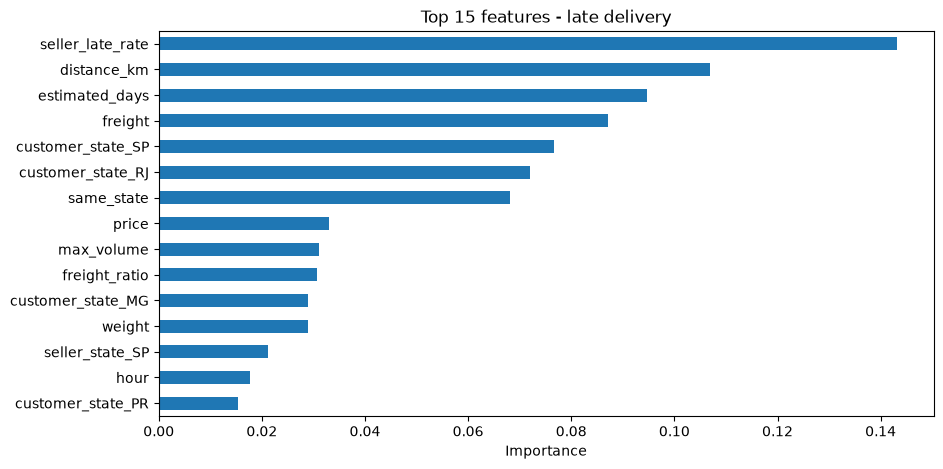

In [15]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

imp.head(15).sort_values().plot(kind="barh", figsize=(10, 5))
plt.title("Top 15 features - late delivery")
plt.xlabel("Importance")
plt.show()

In [16]:
test[["order_id", "order_purchase_timestamp", "customer_state", "seller_state",
      "product_category_name_english", "lr_risk", "rf_risk", "is_late"]].to_csv(path + "late_risk_predictions.csv", index=False)

## Observations

- Late rate by distance: rises steadily from 4.45% (0–100 km) to 6.11% (100–500), 7.12% (500–1000), 9.49% (1000–2000) and 12.03% (2000+ km)
- Same state vs different state: 4.50% late when seller and customer are in the same state, 8.05% when they are not
- Train: 71,118 orders before May 2018 (7.62% late) | Test: 25,352 orders from May 2018 (4.40% late)
- Logistic regression ROC AUC: 0.690 | Random forest ROC AUC: 0.576
- PR AUC: 0.085 (logistic regression) and 0.061 (random forest) vs 0.044 baseline
- Logistic regression is the better model here. The random forest likely learned patterns from the older period, which had a higher late rate, that did not carry over to the test period.
- Riskiest 10% of orders (logistic regression): 10.34% late vs 4.40% overall, 23.5% of all late orders caught
- At the 0.5 cut-off, logistic regression catches 72% of late orders, but only 7% of the orders it flags are actually late
- Strongest predictors (random forest): seller's past late rate, distance, promised delivery days, freight, customer in SP or RJ, and same state
- Business takeaway: the model cannot reliably say "this order will be late", but it can rank orders by risk. Checking the top 10% riskiest orders finds late orders about 2.3 times more often than checking at random. These orders could get extra attention, such as faster shipping, a more realistic delivery date, or an early message to the customer. Sellers with a poor late history and long-distance, cross-state orders are the main risks.
- Limitations: distance is a straight line, not the real route; the test period is only four months and had a lower late rate than training; important causes of delay such as carrier performance and weather are not in the data.